This is AI modified. Takes binary classification models and sweeps thresholds. The AI automated the threshold sweep and add random forest feature importance, everything else was originally lab 6

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lab6_utils import unpack_gridsearch, plot_grid_result
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.inspection import permutation_importance

In [2]:
# Load data and drop any rows with missing values (e.g. NaN in prev_day_rainfall)
data = pd.read_csv('Data/Training_Data.csv').dropna().reset_index(drop=True)

target_class = '%_mem_succs'

# Keep raw continuous target and separate feature matrix X
X = data.drop(columns=[target_class, 'valid_time'], errors='ignore')
y_raw = data[target_class]
feature_names = X.columns

In [3]:
def hypersolve(model, param_grid, X, y, plot=False):
    # 1. Create the pipeline model
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', model)
    ])

    # 2. Construct the GridSearchCV object
    gs = GridSearchCV(pipe, param_grid=param_grid, scoring='accuracy', cv=3, refit='accuracy')
    
    # 3. Run the grid search
    gs.fit(X, y)
    
    # 4. Run unpack_gridsearch to obtain the results dictionary
    result = unpack_gridsearch(gs)

    # 5. Optionally plot the grid result
    if plot:
        plot_grid_result(result)

    return result

In [4]:
# Sweep across thresholds from 0.3 to 0.8
thresholds = np.round(np.arange(0.3, 0.81, 0.1), 2)  # [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

param_grid_lr = {'model__l1_ratio': [0, 1], 'model__C': np.logspace(-3, 1, 5)}
param_grid_rf = {'model__max_features': [3, X.shape[1]], 'model__n_estimators': [2, 42, 82]}
param_grid_ab = {'model__learning_rate': [0.01, 0.1], 'model__n_estimators': [20, 60, 100]}
param_grid_gbt = {'model__learning_rate': [0.01, 0.1], 'model__n_estimators': [20, 60, 100]}

threshold_results = []

for thres in thresholds:
    y_bin = y_raw.between(thres, 1)
    
    # Compute majority-class baseline accuracy for this threshold
    n_pos = y_bin.sum()
    n_neg = len(y_bin) - n_pos
    baseline_acc = max(n_pos, n_neg) / len(y_bin)
    
    # Run grid search for each model
    res_lr = hypersolve(LogisticRegression(solver='liblinear'), param_grid_lr, X, y_bin)
    res_rf = hypersolve(RandomForestClassifier(random_state=42), param_grid_rf, X, y_bin)
    res_ab = hypersolve(AdaBoostClassifier(random_state=42), param_grid_ab, X, y_bin)
    res_gbt = hypersolve(GradientBoostingClassifier(random_state=42), param_grid_gbt, X, y_bin)
    
    threshold_results.append({
        'threshold': thres,
        'pos_rate': n_pos / len(y_bin),
        'baseline_acc': baseline_acc,
        'logreg_acc': res_lr['best_score'],
        'rf_acc': res_rf['best_score'],
        'ab_acc': res_ab['best_score'],
        'gbt_acc': res_gbt['best_score'],
        'best_rf_estimator': res_rf['best_estimator']
    })

results_df = pd.DataFrame(threshold_results)
print(results_df.drop(columns=['best_rf_estimator']).to_string(index=False))

 threshold  pos_rate  baseline_acc  logreg_acc   rf_acc   ab_acc  gbt_acc
       0.3  0.919753      0.919753    0.919753 0.919753 0.919753 0.919753
       0.4  0.864198      0.864198    0.864198 0.820988 0.864198 0.864198
       0.5  0.820988      0.820988    0.820988 0.728395 0.753086 0.820988
       0.6  0.660494      0.660494    0.660494 0.580247 0.660494 0.660494
       0.7  0.500000      0.500000    0.500000 0.512346 0.555556 0.543210
       0.8  0.401235      0.598765    0.598765 0.567901 0.623457 0.604938


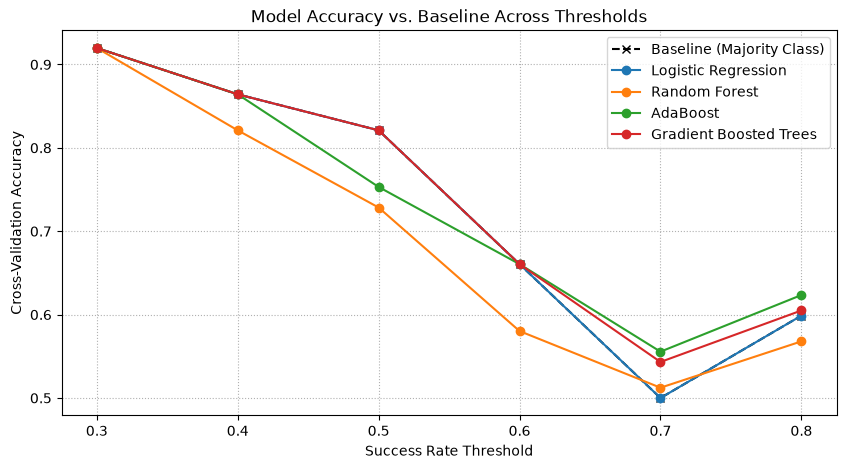

In [5]:
# Plot Model CV Accuracy vs. Majority-Class Baseline Across Thresholds
plt.figure(figsize=(10, 5))
plt.plot(results_df['threshold'], results_df['baseline_acc'], 'k--', marker='x', label='Baseline (Majority Class)')
plt.plot(results_df['threshold'], results_df['logreg_acc'], marker='o', label='Logistic Regression')
plt.plot(results_df['threshold'], results_df['rf_acc'], marker='o', label='Random Forest')
plt.plot(results_df['threshold'], results_df['ab_acc'], marker='o', label='AdaBoost')
plt.plot(results_df['threshold'], results_df['gbt_acc'], marker='o', label='Gradient Boosted Trees')

plt.xlabel('Success Rate Threshold')
plt.ylabel('Cross-Validation Accuracy')
plt.title('Model Accuracy vs. Baseline Across Thresholds')
plt.legend()
plt.grid(True, linestyle=':')
plt.show()